# 확률·통계: 손실 함수의 수학적 기반

이 노트북에서 하는 일

1. 정규분포 N(0, 1)과 N(2, 0.5)의 PDF를 한 Figure에 비교한다.
2. 베르누이 분포 B(0.3)과 B(0.7)의 PMF를 한 Figure에 비교한다.
3. 소프트맥스를 구현하고 출력의 합이 1과 1e-6 이내로 같은지 확인한다.
4. **MSE 최소화 = 정규분포 가정 하의 MLE** 를 수식으로 유도하고 숫자로 확인한다.
5. **Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정 하의 MLE** 를 수식으로 유도하고 숫자로 확인한다.
6. (보너스) 엔트로피, KL-Divergence, Cross-Entropy를 직접 구현한다.

모든 계산은 NumPy로 하고, 그림은 Matplotlib으로 그려 `outputs/`에 PNG로 저장한다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent / "src"))  # src/ 모듈을 불러오기 위해
from calculus import numerical_gradient
from plot_style import BLUE, GRAY, GREEN, ORANGE, RED, save_figure, setup_style

np.random.seed(42)
setup_style()

## 1. 정규분포 PDF

정규분포 $N(\mu, \sigma^2)$ 는 평균 $\mu$ 근처에 값이 몰려 있고 멀어질수록 드물어지는 연속 분포다. 확률밀도함수(PDF)는

$$
p(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left( -\frac{(x-\mu)^2}{2\sigma^2} \right)
$$

- $\mu$ (뮤): 평균, 곡선의 중심
- $\sigma^2$: 분산, $\sigma$ (시그마): 표준편차. 클수록 넓고 낮게 퍼진다.
- 곡선 아래 전체 넓이는 1이다. PDF의 **높이 자체는 확률이 아니므로** 1보다 클 수도 있다.

**N(2, 0.5)의 0.5는 무엇인가?** 통계에서 $N(\mu, \sigma^2)$ 는 두 번째 자리에 **분산**을 쓰는 것이 표준 표기다. 이 노트북은 **분산 0.5 (표준편차 $\sqrt{0.5} \approx 0.707$)** 로 해석한다. 비교를 위해 표준편차 0.5로 해석한 곡선도 점선으로 함께 그린다.

N(0, 1): $\mu=0,\ \sigma^2=1$                           곡선 아래 넓이 = 0.999968, 최고점 = 0.3989
N(2, 0.5): $\mu=2,\ \sigma^2=0.5\ (\sigma \approx 0.707)$ 곡선 아래 넓이 = 0.999989, 최고점 = 0.5642
참고: $\sigma=0.5\ (\sigma^2=0.25)$ 로 해석한 경우              곡선 아래 넓이 = 1.000000, 최고점 = 0.7979


[저장] outputs/prob_normal_pdf.png


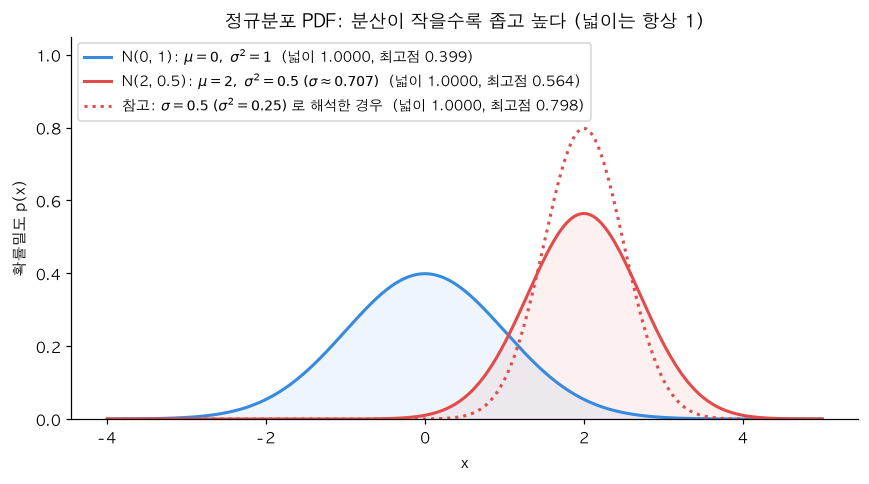

In [2]:
def normal_pdf(x, mu, var):
    """정규분포 N(mu, var)의 확률밀도 p(x) = exp(-(x-mu)²/(2var)) / sqrt(2π var).

    Args:
        x: 값 (배열 가능).
        mu: 평균 μ.
        var: 분산 σ².

    Returns:
        x와 같은 shape의 확률밀도.
    """
    return np.exp(-((x - mu) ** 2) / (2 * var)) / np.sqrt(2 * np.pi * var)


xs = np.linspace(-4, 5, 1000)
curves = [
    (r"N(0, 1): $\mu=0,\ \sigma^2=1$", normal_pdf(xs, 0, 1), BLUE, "-"),
    (r"N(2, 0.5): $\mu=2,\ \sigma^2=0.5\ (\sigma \approx 0.707)$", normal_pdf(xs, 2, 0.5), RED, "-"),
    (r"참고: $\sigma=0.5\ (\sigma^2=0.25)$ 로 해석한 경우", normal_pdf(xs, 2, 0.25), RED, ":"),
]
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, ys, c, ls in curves:
    area = np.trapezoid(ys, xs)
    ax.plot(xs, ys, color=c, ls=ls, lw=2, label=f"{label}  (넓이 {area:.4f}, 최고점 {ys.max():.3f})")
    print(f"{label:<55} 곡선 아래 넓이 = {area:.6f}, 최고점 = {ys.max():.4f}")
ax.fill_between(xs, normal_pdf(xs, 0, 1), color=BLUE, alpha=0.08)
ax.fill_between(xs, normal_pdf(xs, 2, 0.5), color=RED, alpha=0.08)
ax.set(xlabel="x", ylabel="확률밀도 p(x)",
       title="정규분포 PDF: 분산이 작을수록 좁고 높다 (넓이는 항상 1)")
ax.legend(fontsize=9, loc="upper left")
ax.set_ylim(0, 1.05)
save_figure(fig, "prob_normal_pdf")
plt.show()

## 2. 베르누이 분포 PMF

베르누이 분포 $B(p)$ 는 결과가 1(성공) 또는 0(실패) 두 가지뿐인 분포다. 확률질량함수(PMF)는

$$
P(Y = y) = p^{y} (1-p)^{1-y}, \qquad y \in \{0, 1\}
$$

$y = 1$ 이면 $p$, $y = 0$ 이면 $1 - p$ 가 된다. 이산 분포라 **막대 높이가 곧 확률**이고, 막대 높이의 합은 1이다.

B(0.3): P(0) = 0.7, P(1) = 0.3, 합 = 1.0
B(0.7): P(0) = 0.3, P(1) = 0.7, 합 = 1.0


[저장] outputs/prob_bernoulli_pmf.png


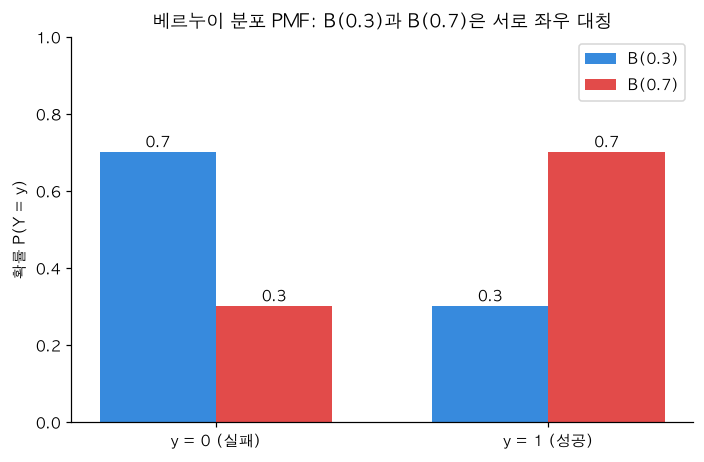

In [3]:
def bernoulli_pmf(y, p):
    """베르누이 분포 B(p)의 확률 P(Y=y) = p^y (1-p)^(1-y), y ∈ {0, 1}.

    Args:
        y: 0 또는 1 (배열 가능).
        p: 1이 나올 확률.

    Returns:
        y와 같은 shape의 확률.
    """
    y = np.asarray(y)
    return p**y * (1 - p) ** (1 - y)


ys = np.array([0, 1])
width = 0.35
fig, ax = plt.subplots(figsize=(6.5, 4.3))
for shift, p, c in [(-width / 2, 0.3, BLUE), (width / 2, 0.7, RED)]:
    probs = bernoulli_pmf(ys, p)
    bars = ax.bar(ys + shift, probs, width, color=c, label=f"B({p})")
    ax.bar_label(bars, fmt="%.1f")
    print(f"B({p}): P(0) = {probs[0]:.1f}, P(1) = {probs[1]:.1f}, 합 = {probs.sum():.1f}")
ax.set(xticks=[0, 1], xticklabels=["y = 0 (실패)", "y = 1 (성공)"], ylim=(0, 1),
       ylabel="확률 P(Y = y)", title="베르누이 분포 PMF: B(0.3)과 B(0.7)은 서로 좌우 대칭")
ax.legend()
save_figure(fig, "prob_bernoulli_pmf")
plt.show()

## 3. 소프트맥스

소프트맥스는 점수(logit) 벡터 $z$ 를 **합이 1인 확률 벡터**로 바꾼다.

$$
\text{softmax}(z)_k = \frac{e^{z_k}}{\sum_j e^{z_j}}
$$

**수치 안정성**: $z$ 가 크면 $e^{z}$ 가 너무 커져 `inf`가 된다(오버플로). 모든 점수에서 같은 수 $c = \max(z)$ 를 빼도 결과는 같으므로 ($\frac{e^{z_k - c}}{\sum_j e^{z_j - c}} = \frac{e^{-c} e^{z_k}}{e^{-c} \sum_j e^{z_j}}$), 최댓값을 빼고 계산한다. 그러면 가장 큰 지수가 $e^0 = 1$ 이 되어 오버플로가 생기지 않는다.

In [4]:
def softmax(z):
    """수치적으로 안정한 소프트맥스. 최댓값을 빼서 오버플로를 막는다.

    softmax(z)_k = exp(z_k - max(z)) / Σ_j exp(z_j - max(z))

    Args:
        z: 점수 벡터. shape (K,).

    Returns:
        확률 벡터. shape (K,), 합 = 1.
    """
    z = np.asarray(z, dtype=float)
    e = np.exp(z - np.max(z))
    return e / np.sum(e)


def softmax_naive(z):
    """최댓값을 빼지 않은 소프트맥스 (비교용). 큰 입력에서 nan이 된다."""
    e = np.exp(np.asarray(z, dtype=float))
    return e / np.sum(e)


tests = {
    "작은 점수 [2, 1, 0.1]": np.array([2.0, 1.0, 0.1]),
    "음수 포함 [-3, 0, 3, 1]": np.array([-3.0, 0.0, 3.0, 1.0]),
    "큰 점수 [1000, 1001, 1002]": np.array([1000.0, 1001.0, 1002.0]),
    "무작위 10개 (seed 42)": np.random.randn(10) * 5,
}
for name, z in tests.items():
    p = softmax(z)
    diff = abs(p.sum() - 1.0)
    with np.errstate(over="ignore", invalid="ignore"):
        naive = softmax_naive(z)
    print(f"{name:<26} 합 = {p.sum():.10f}, |합 - 1| = {diff:.1e} → {'통과' if diff <= 1e-6 else '실패'}"
          f" | 안정화 안 한 버전: {'nan 발생' if np.isnan(naive).any() else '정상'}")
    assert diff <= 1e-6
print("\n[2, 1, 0.1] →", np.round(softmax([2.0, 1.0, 0.1]), 4))

작은 점수 [2, 1, 0.1]          합 = 1.0000000000, |합 - 1| = 0.0e+00 → 통과 | 안정화 안 한 버전: 정상
음수 포함 [-3, 0, 3, 1]        합 = 1.0000000000, |합 - 1| = 1.1e-16 → 통과 | 안정화 안 한 버전: 정상
큰 점수 [1000, 1001, 1002]    합 = 1.0000000000, |합 - 1| = 1.1e-16 → 통과 | 안정화 안 한 버전: nan 발생
무작위 10개 (seed 42)          합 = 1.0000000000, |합 - 1| = 1.1e-16 → 통과 | 안정화 안 한 버전: 정상

[2, 1, 0.1] → [0.659  0.2424 0.0986]


[저장] outputs/prob_softmax.png


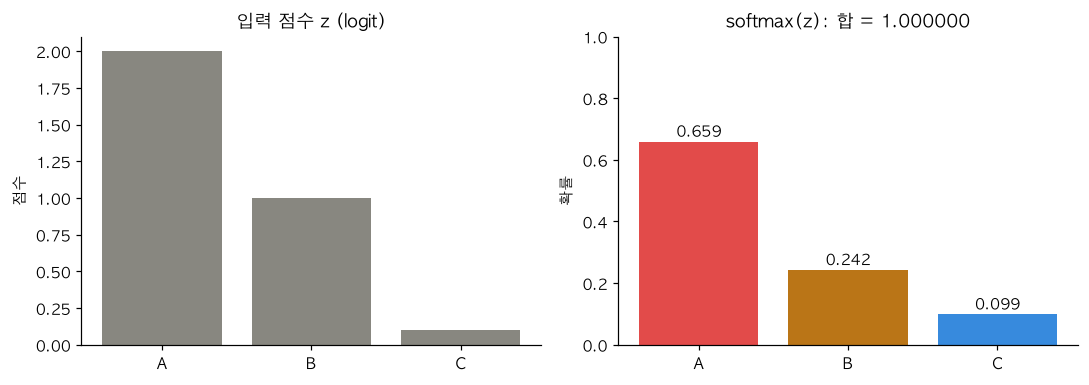

In [5]:
z = np.array([2.0, 1.0, 0.1])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.bar(["A", "B", "C"], z, color=GRAY)
a1.set(title="입력 점수 z (logit)", ylabel="점수")
probs = softmax(z)
bars = a2.bar(["A", "B", "C"], probs, color=[RED, ORANGE, BLUE])
a2.bar_label(bars, fmt="%.3f")
a2.set(title=f"softmax(z): 합 = {probs.sum():.6f}", ylabel="확률", ylim=(0, 1))
save_figure(fig, "prob_softmax")
plt.show()

## 4. MSE 최소화 = 정규분포 가정 하의 MLE

### 최대우도추정(MLE)이란

**우도(likelihood)** 는 "모델 파라미터 $\theta$ 가 이렇다면, 지금 가진 데이터가 나올 확률(밀도)"이다. **MLE** 는 이 우도를 가장 크게 만드는 $\theta$ 를 고른다. 데이터 $n$ 개가 서로 독립이면 우도는 각 데이터 확률의 곱이다.

$$
\hat{\theta}_{\text{MLE}} = \arg\max_{\theta} \prod_{i=1}^{n} p(y_i \mid x_i; \theta)
$$

곱은 다루기 어렵고 아주 작은 수가 되어 컴퓨터에서 0이 되기 쉽다. $\log$ 는 증가 함수라 최댓값의 위치를 바꾸지 않고 곱을 합으로 바꾸므로, **로그 우도**를 최대화한다. 손실은 작게 만드는 것이 관례이므로 부호를 바꿔 **음의 로그 우도(NLL)** 를 최소화한다.

$$
\arg\max_{\theta} \prod_i p(y_i \mid x_i) = \arg\max_{\theta} \sum_i \log p(y_i \mid x_i) = \arg\min_{\theta} \left( -\sum_i \log p(y_i \mid x_i) \right)
$$

### 유도

**가정**: 정답은 모델 예측 $f(x)$ 에 정규분포 잡음이 더해진 것이다.

$$
y = f(x) + \varepsilon, \quad \varepsilon \sim N(0, \sigma^2)
\quad\Rightarrow\quad
p(y \mid x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left( -\frac{(y - f(x))^2}{2\sigma^2} \right)
$$

로그를 씌우면 ($\log e^{a} = a$, $\log \frac{1}{b} = -\log b$)

$$
\log p(y_i \mid x_i) = -\frac{(y_i - f(x_i))^2}{2\sigma^2} - \log \sqrt{2\pi\sigma^2}
$$

따라서

$$
\begin{aligned}
\arg\max_{\theta} \sum_i \log p(y_i \mid x_i)
&= \arg\max_{\theta} \sum_i \left[ -\frac{(y_i - f(x_i))^2}{2\sigma^2} - \log\sqrt{2\pi\sigma^2} \right] \\
&= \arg\max_{\theta} \left( -\frac{1}{2\sigma^2} \sum_i (y_i - f(x_i))^2 \right) && \text{(θ와 무관한 상수 항 제거)} \\
&= \arg\min_{\theta} \sum_i (y_i - f(x_i))^2 && \text{(양수 } \tfrac{1}{2\sigma^2} \text{ 제거, max} \to \text{min)} \\
&= \arg\min_{\theta} \frac{1}{n} \sum_i (y_i - f(x_i))^2 = \arg\min_{\theta} \text{MSE}
\end{aligned}
$$

**결론**: 오차가 정규분포를 따른다고 가정하면, 우도를 최대화하는 것과 MSE를 최소화하는 것은 **같은 θ** 를 고른다. $\sigma$ 의 값은 결과(어떤 θ가 최선인지)에 영향을 주지 않는다.

### 숫자로 확인

$y = 2x + 1 + \varepsilon$ ($\varepsilon \sim N(0, 0.5^2)$) 로 데이터 50개를 만들고, 절편은 1로 고정한 채 기울기 $w$ 를 바꿔 가며 MSE와 NLL을 계산한다. 두 곡선의 최솟값 위치가 같아야 한다.

MSE를 최소로 만드는 w = 2.0550
NLL을 최소로 만드는 w = 2.0550  (우도 최대)
→ 같은 w
NLL = n/(2σ²) × MSE + 상수 확인: 최대 차이 = 5.7e-14


[저장] outputs/prob_mse_mle.png


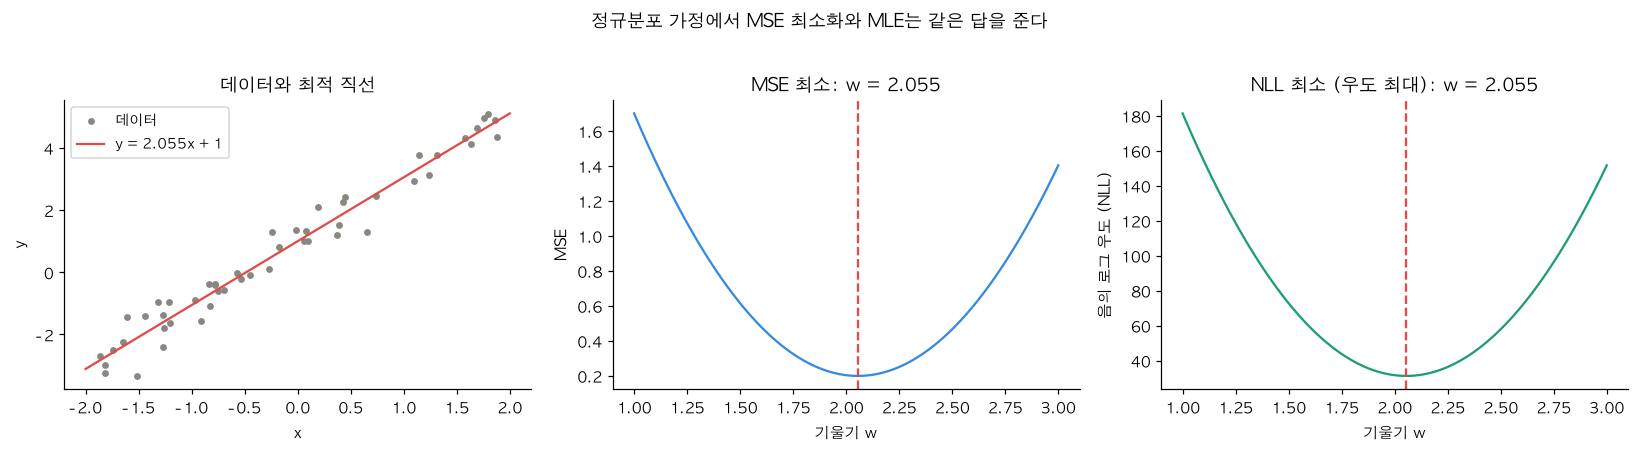

In [6]:
n = 50
x_data = np.random.uniform(-2, 2, n)
sigma = 0.5
y_data = 2 * x_data + 1 + np.random.normal(0, sigma, n)

ws = np.linspace(1.0, 3.0, 2001)
mse = np.array([np.mean((y_data - (w * x_data + 1)) ** 2) for w in ws])
nll = np.array([-np.sum(np.log(normal_pdf(y_data, w * x_data + 1, sigma**2))) for w in ws])

w_mse, w_nll = ws[np.argmin(mse)], ws[np.argmin(nll)]
print(f"MSE를 최소로 만드는 w = {w_mse:.4f}")
print(f"NLL을 최소로 만드는 w = {w_nll:.4f}  (우도 최대)")
print(f"→ {'같은 w' if np.isclose(w_mse, w_nll) else '다른 w'}")
print(f"NLL = n/(2σ²) × MSE + 상수 확인: 최대 차이 = "
      f"{np.max(np.abs(nll - (n / (2 * sigma**2) * mse + n * np.log(np.sqrt(2 * np.pi * sigma**2))))):.1e}")

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4))
a1.scatter(x_data, y_data, s=12, color=GRAY, label="데이터")
xx = np.linspace(-2, 2, 2)
a1.plot(xx, w_mse * xx + 1, color=RED, label=f"y = {w_mse:.3f}x + 1")
a1.set(xlabel="x", ylabel="y", title="데이터와 최적 직선")
a1.legend(fontsize=9)
a2.plot(ws, mse, color=BLUE)
a2.axvline(w_mse, color=RED, ls="--")
a2.set(xlabel="기울기 w", ylabel="MSE", title=f"MSE 최소: w = {w_mse:.3f}")
a3.plot(ws, nll, color=GREEN)
a3.axvline(w_nll, color=RED, ls="--")
a3.set(xlabel="기울기 w", ylabel="음의 로그 우도 (NLL)", title=f"NLL 최소 (우도 최대): w = {w_nll:.3f}")
fig.suptitle("정규분포 가정에서 MSE 최소화와 MLE는 같은 답을 준다", y=1.02)
save_figure(fig, "prob_mse_mle")
plt.show()

## 5. Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정 하의 MLE

### 5-1. 이진 분류: 베르누이 분포

**가정**: 정답 $y \in \{0, 1\}$ 은 모델이 예측한 확률 $\hat{y} = f(x)$ 를 성공 확률로 하는 베르누이 분포를 따른다.

$$
p(y \mid x) = \hat{y}^{\,y} (1 - \hat{y})^{1-y}
$$

로그를 씌우면 ($\log a^b = b \log a$)

$$
\log p(y_i \mid x_i) = y_i \log \hat{y}_i + (1 - y_i) \log (1 - \hat{y}_i)
$$

따라서

$$
\arg\max_{\theta} \sum_i \log p(y_i \mid x_i)
= \arg\min_{\theta} \; -\sum_i \left[ y_i \log \hat{y}_i + (1 - y_i) \log (1 - \hat{y}_i) \right]
= \arg\min_{\theta} \text{BCE}
$$

음의 로그 우도가 **Binary Cross-Entropy 그 자체**다. 이번에는 상수를 지울 필요도 없이 그대로 같다.

### 5-2. 다중 분류: 카테고리 분포

**가정**: 정답은 $K$ 개 클래스 중 하나이고, 원-핫 벡터 $y = (y_1, \dots, y_K)$ (정답 클래스만 1)로 쓴다. 모델은 소프트맥스로 확률 $\hat{y} = \text{softmax}(z)$ 를 낸다.

$$
p(y \mid x) = \prod_{k=1}^{K} \hat{y}_k^{\,y_k}
\quad\Rightarrow\quad
\log p(y \mid x) = \sum_{k=1}^{K} y_k \log \hat{y}_k
$$

$$
\arg\max_{\theta} \sum_i \log p(y_i \mid x_i) = \arg\min_{\theta} \; -\sum_i \sum_k y_{i,k} \log \hat{y}_{i,k} = \arg\min_{\theta} \text{CE}
$$

원-핫이라 실제로는 **정답 클래스의 확률에 로그를 씌운 값** $-\log \hat{y}_{\text{정답}}$ 만 남는다. 정답 확률이 1에 가까우면 손실이 0, 0에 가까우면 손실이 매우 커진다. 베르누이는 $K = 2$ 인 특별한 경우다.

**MSE와 CE의 차이 정리**

| | MSE | Cross-Entropy |
|---|---|---|
| 가정하는 분포 | 정규분포 (연속값 + 잡음) | 베르누이 / 카테고리 (클래스) |
| 주로 쓰는 문제 | 회귀 (값 예측) | 분류 (클래스 예측) |
| MLE와의 관계 | 상수와 배율을 지우면 같다 | 음의 로그 우도와 정확히 같다 |

### 숫자로 확인 1: 동전 던지기

동전을 10번 던져 앞면(1)이 7번 나왔다. 앞면 확률 $p$ 를 바꿔 가며 BCE(평균)와 우도를 계산하면, BCE 최소 = 우도 최대 = **표본 비율 0.7** 이 되어야 한다.

BCE 최소 p = 0.70, 우도 최대 p = 0.70, 표본 비율 = 0.70


[저장] outputs/prob_bce_mle.png


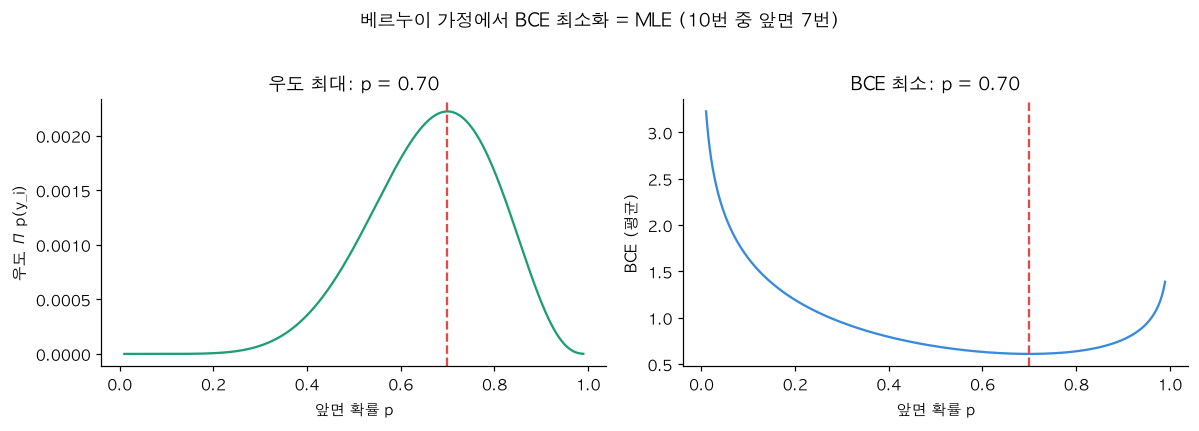

In [7]:
coins = np.array([1, 1, 1, 0, 1, 1, 0, 1, 0, 1])   # 앞면 7번
ps = np.linspace(0.01, 0.99, 981)
bce = np.array([-np.mean(coins * np.log(p) + (1 - coins) * np.log(1 - p)) for p in ps])
likelihood = np.array([np.prod(bernoulli_pmf(coins, p)) for p in ps])
p_bce, p_lik = ps[np.argmin(bce)], ps[np.argmax(likelihood)]
print(f"BCE 최소 p = {p_bce:.2f}, 우도 최대 p = {p_lik:.2f}, 표본 비율 = {coins.mean():.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(ps, likelihood, color=GREEN)
a1.axvline(p_lik, color=RED, ls="--")
a1.set(xlabel="앞면 확률 p", ylabel="우도 Π p(y_i)", title=f"우도 최대: p = {p_lik:.2f}")
a2.plot(ps, bce, color=BLUE)
a2.axvline(p_bce, color=RED, ls="--")
a2.set(xlabel="앞면 확률 p", ylabel="BCE (평균)", title=f"BCE 최소: p = {p_bce:.2f}")
fig.suptitle("베르누이 가정에서 BCE 최소화 = MLE (10번 중 앞면 7번)", y=1.02)
save_figure(fig, "prob_bce_mle")
plt.show()

### 숫자로 확인 2: 소프트맥스 + Cross-Entropy의 기울기

4장 역전파에서 sigmoid + BCE의 기울기가 $\hat{y} - y$ 였던 것처럼, 소프트맥스 + CE의 기울기도

$$
\frac{\partial\, \text{CE}}{\partial z_k} = \hat{y}_k - y_k
$$

로 "예측 − 정답" 형태가 된다. `src/calculus.py`의 중심차분으로 확인한다.

In [8]:
def cross_entropy(z, y_onehot):
    """소프트맥스 확률에 대한 Cross-Entropy -Σ y_k log softmax(z)_k."""
    return -np.sum(y_onehot * np.log(softmax(z)))


z = np.array([2.0, 1.0, 0.1])
y_onehot = np.array([0.0, 1.0, 0.0])          # 정답은 두 번째 클래스
analytic = softmax(z) - y_onehot
numeric = numerical_gradient(lambda v: cross_entropy(v, y_onehot), z)
print("CE =", round(cross_entropy(z, y_onehot), 4), "= -log(정답 확률", round(softmax(z)[1], 4), ")")
print("공식 ŷ - y      :", np.round(analytic, 6))
print("중심차분 기울기  :", np.round(numeric, 6))
print("최대 차이        :", f"{np.max(np.abs(analytic - numeric)):.1e}")

CE = 1.417 = -log(정답 확률 0.2424 )
공식 ŷ - y      : [ 0.659001 -0.757567  0.098566]
중심차분 기울기  : [ 0.659001 -0.757567  0.098566]
최대 차이        : 6.9e-12


## 6. (보너스) 정보 이론: 엔트로피, KL-Divergence, Cross-Entropy

이산 분포 $p$ (정답 분포)와 $q$ (모델 분포)에 대해

$$
H(p) = -\sum_k p_k \log p_k, \qquad
D_{KL}(p \,\|\, q) = \sum_k p_k \log \frac{p_k}{q_k}, \qquad
H(p, q) = -\sum_k p_k \log q_k
$$

- **엔트로피** $H(p)$: 분포의 불확실성. 고르게 퍼질수록 크다.
- **KL-Divergence**: $q$ 가 $p$ 와 얼마나 다른가. 항상 0 이상이고, 같으면 0이다.
- **Cross-Entropy**: $H(p, q) = H(p) + D_{KL}(p \,\|\, q)$. 정답 분포 $p$ 는 고정이라 $H(p)$ 는 상수이므로, **CE를 최소화하는 것 = KL을 최소화하는 것 = 모델 분포를 정답 분포에 가깝게 만드는 것** 이다.

In [9]:
def entropy(p):
    """엔트로피 H(p) = -Σ p log p (p = 0 인 항은 0으로 본다)."""
    p = np.asarray(p, dtype=float)
    nz = p > 0
    return -np.sum(p[nz] * np.log(p[nz]))


def kl_divergence(p, q):
    """KL(p || q) = Σ p log(p / q) (p = 0 인 항은 0으로 본다)."""
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    nz = p > 0
    return np.sum(p[nz] * np.log(p[nz] / q[nz]))


def cross_entropy_pq(p, q):
    """Cross-Entropy H(p, q) = -Σ p log q."""
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    nz = p > 0
    return -np.sum(p[nz] * np.log(q[nz]))


p = np.array([0.7, 0.2, 0.1])
for name, q in [("q = p", p), ("q = [0.5, 0.3, 0.2]", np.array([0.5, 0.3, 0.2])),
                ("q = 균등 [1/3, 1/3, 1/3]", np.ones(3) / 3)]:
    H, KL, CE = entropy(p), kl_divergence(p, q), cross_entropy_pq(p, q)
    print(f"{name:<26} H(p) = {H:.4f}, KL = {KL:.4f}, CE = {CE:.4f}, H + KL = {H + KL:.4f} "
          f"→ {'CE = H + KL' if np.isclose(CE, H + KL) else '불일치'}")

q = p                      H(p) = 0.8018, KL = 0.0000, CE = 0.8018, H + KL = 0.8018 → CE = H + KL
q = [0.5, 0.3, 0.2]        H(p) = 0.8018, KL = 0.0851, CE = 0.8869, H + KL = 0.8869 → CE = H + KL
q = 균등 [1/3, 1/3, 1/3]     H(p) = 0.8018, KL = 0.2968, CE = 1.0986, H + KL = 1.0986 → CE = H + KL


## 7. 정리

- 정규분포는 분산이 작을수록 좁고 높아지며, 곡선 아래 넓이는 항상 1이다. N(2, 0.5)는 분산 0.5로 해석했다.
- 베르누이 분포 B(0.3)과 B(0.7)은 0과 1의 확률이 서로 뒤바뀐 대칭 관계다.
- 소프트맥스는 최댓값을 빼서 계산하면 [1000, 1001, 1002] 같은 큰 입력에서도 오버플로 없이 합이 1이 된다.
- **오차가 정규분포**라고 가정하면 우도를 최대화하는 것은 **MSE 최소화**와 같다 (회귀).
- **정답이 베르누이/카테고리 분포**를 따른다고 가정하면 음의 로그 우도는 **Cross-Entropy** 그 자체다 (분류).
- 즉 손실 함수는 임의로 고른 것이 아니라, **데이터가 어떤 분포에서 왔다고 가정하느냐**에서 나온다.